In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
from pathlib import Path
import os, sys
from dotenv import load_dotenv


In [4]:
from datasets import load_dataset
import wandb
import numpy as np

import torch
from torch.nn import functional as F
from transformers import AutoModelForMultimodalLM, AutoProcessor

Failed to load /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
Failed to load /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_cutlass_90a.abi3.so
W1124 02:44:10.126000 3880870 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 02:44:10.198000 3880870 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque

In [5]:
from PIL import Image
import requests
from io import BytesIO

In [6]:
print("CUDA:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(torch.cuda.get_device_name(i))

CUDA: True
GPU count: 8
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40


In [7]:
try:
    project_root = next(p for p in Path().cwd().resolve().parents if (p /"env.env").exists())
except StopIteration:
    # Fallback to current working directory if not found
    project_root = Path.cwd()

sys.path.insert(0, str(project_root))

print(f"Project Root: {project_root}")
load_dotenv((project_root /'env.env').resolve())
data_dir = project_root / "datasets"

Project Root: /coc/scratch/vchopra/learning_env/Deep-Learning


In [8]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

### Step-1: - Setup Model 

In [9]:
import torchao
from torchao.quantization import quantize_, Int8WeightOnlyConfig

In [10]:
MODEL_ID = "thinkingmachines/TML-d24-varloop-research"
MAX_MEMORY = {i: "35GiB" for i in range(2)}

In [11]:
def build_device_map(gpu0=0, gpu1=1):
    device_map = {
        "model.vision_tower": gpu0,
        "model.language_model.embed_tokens": gpu0,
        "model.language_model.norm": gpu0,
        "model.language_model.final_input": gpu0,
        "model.language_model.message_input": gpu1,
        "lm_head": gpu0,
        "logit_softcap": gpu0,
    }

    for i in range(24):
        device_map[f"model.language_model.layers.{i}"] = (
            gpu1 if 6 <= i < 18 else gpu0
        )

    return device_map

DEVICE_MAP = build_device_map()

In [12]:
def load_model(R=3):
    assert 1 <= R <= 5
    # assert torch.cuda.device_count() >= 4
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model, loading_info = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, device_map="balanced", max_memory=MAX_MEMORY, experts_implementation="grouped_mm",
                                                                   dtype=torch.bfloat16, text_config={"loop_num_passes": R}, output_loading_info=True)

    model.eval()
    model.requires_grad_(False)

    print("Loop count:", model.config.text_config.loop_num_passes)
    print("Device map:", model.hf_device_map)

    return model, processor, loading_info
model, processor, loading_info = load_model(R=1)

[transformers] Unknown quantization type, got modelopt - supported types are: ['awq', 'bitsandbytes_4bit', 'bitsandbytes_8bit', 'gptq', 'aqlm', 'quanto', 'quark', 'fouroversix', 'fp_quant', 'eetq', 'higgs', 'hqq', 'compressed-tensors', 'fbgemm_fp8', 'torchao', 'bitnet', 'vptq', 'spqr', 'fp8', 'gguf', 'nvfp4', 'mxfp8', 'auto-round', 'mxfp4', 'metal', 'sinq', 'gemma']. Hence, we will skip the quantization. To remove the warning, you can delete the quantization_config attribute in config.json


Loading weights:   0%|          | 0/1115 [00:00<?, ?it/s]

Loop count: 3
Device map: {'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 0, 'model.language_model.layers.12': 1, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.layers.21': 1, 'model.language_model.layers.22': 1, 'model.language_model.layers.23': 1, 'model.language_model.norm': 1, 'model.language_model.f

In [13]:
memory = {0: 0, 1: 0}

for name, p in model.named_parameters():
    for module, gpu in DEVICE_MAP.items():
        if name == module or name.startswith(module + "."):
            memory[gpu] += p.numel() * p.element_size()
            break
    else:
        print("Unmapped:", name)

for gpu, size in memory.items():
    print(f"GPU {gpu}: {size / 1024**3:.2f} GiB")

GPU 0: 25.71 GiB
GPU 1: 23.48 GiB


In [14]:
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.memory_allocated(i)/1024**3:.2f} GiB")

GPU 0: 24.30 GiB
GPU 1: 24.91 GiB
GPU 2: 0.00 GiB
GPU 3: 0.00 GiB
GPU 4: 0.00 GiB
GPU 5: 0.00 GiB
GPU 6: 0.00 GiB
GPU 7: 0.00 GiB


In [15]:
from collections import Counter

print("Missing keys:", loading_info.get("missing_keys"))
print("Unexpected keys:", loading_info.get("unexpected_keys"))
print("Mismatched keys:", loading_info.get("mismatched_keys"))

print("Loop count:", model.config.text_config.loop_num_passes)

dtypes = Counter()

for p in model.parameters():
    dtypes[str(p.dtype)] += p.numel()

for dtype, count in dtypes.items():
    print(dtype, f"{count / 1e9:.3f}B parameters")

print("Model footprint:", model.get_memory_footprint() / 1024**3, "GiB")

for i in range(4):
    print(f"GPU {i}:",torch.cuda.memory_allocated(i) / 1024**3, "GiB")

Missing keys: set()
Unexpected keys: set()
Mismatched keys: set()
Loop count: 3
torch.bfloat16 26.364B parameters
torch.float32 0.022B parameters
Model footprint: 49.189661145210266 GiB
GPU 0: 24.304137706756592 GiB
GPU 1: 24.908749103546143 GiB
GPU 2: 0.0 GiB
GPU 3: 0.0 GiB


In [16]:
print(model.hf_device_map)

assert all(str(d) not in ("cpu", "disk", "meta") for d in model.hf_device_map.values())

{'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 0, 'model.language_model.layers.12': 1, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.layers.21': 1, 'model.language_model.layers.22': 1, 'model.language_model.layers.23': 1, 'model.language_model.norm': 1, 'model.language_model.final_input': 1, 'model.lan

#### Step-2: - Test the inference 

In [17]:

def prepare_inputs(content):
    return processor.apply_chat_template([{"role": "user", "content": content}], reasoning_effort="none", add_generation_prompt=True, 
        tokenize=True, return_dict=True, return_tensors="pt").to(model.device)

import time

def synchronize():
    for i in range(torch.cuda.device_count()):
        torch.cuda.synchronize(i)

inputs = prepare_inputs([
    {"type": "text", "text": "What is 12 multiplied by 5?"}
])

print("Input tokens:", inputs["input_ids"].shape[-1])

@torch.inference_mode()
def benchmark(n=1):
    synchronize()
    start = time.perf_counter()

    outputs = model.generate(
        **inputs,
        max_new_tokens=n,
        do_sample=False,
        use_cache=True,
    )

    synchronize()
    elapsed = time.perf_counter() - start

    tokens = outputs[0][inputs["input_ids"].shape[-1]:]

    print("Time:", round(elapsed, 3), "seconds")
    print("Generated tokens:", len(tokens))
    print("Output:", processor.decode(tokens))


@torch.inference_mode()
def inference(content):
    inputs = prepare_inputs(content)
    outputs = model.generate(**inputs, max_new_tokens=128, do_sample=False)
    return processor.decode(outputs[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True)

Input tokens: 22


In [18]:
cfg = model.config.text_config

print("Experts:", cfg._experts_implementation)
print("Attention:", cfg._attn_implementation)
print("KV cache:", model.generation_config.use_cache)
print("Device map:", model.hf_device_map)

from importlib.util import find_spec
print("Causal Conv1D:", find_spec("causal_conv1d") is not None)

Experts: grouped_mm
Attention: eager
KV cache: None
Device map: {'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 0, 'model.language_model.layers.12': 1, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.layers.21': 1, 'model.language_model.layers.22': 1, 'model.language_model.layers.23': 1, 'model.language_m

In [19]:
print(benchmark(1))
print(benchmark(8))

Time: 1.197 seconds
Generated tokens: 1
Output: <|message_model|>
None
Time: 2.143 seconds
Generated tokens: 8
Output: <|message_model|><|content_thinking|>The user is asking a simple
None


In [20]:
# Text inference
print(inference([{"type": "text", "text": "What is 12 multiplied by 5?"}]))

The user is asking a simple arithmetic question: 12 multiplied by 5. Need answer. Compute 12*5 = 60. Need final concise. Ensure no extra unnecessary detail. Could say 60.60


In [21]:
# Image inference
# print(inference([{"type": "image", "image": "test.jpg"}, {"type": "text", "text": "What animal is in this image?"}]))

In [22]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "url": "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/p-blog/candy.JPG"},
            {"type": "text", "text": "What animal is on the candy?"}
        ]
    },
]
content = messages[0]["content"]

In [23]:
url = messages[0]["content"][0]["url"]

response = requests.get(url, timeout=30)
response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")

print("Image resolution:", image.size)

inputs = prepare_inputs(content)

print("Total tokens:", inputs["input_ids"].shape[-1])
print("Image grid:", inputs.get("image_grid_thw"))

print("Visual tokens:", (inputs["input_ids"] == model.config.image_token_id).sum().item())

[transformers] torchcodec is installed but failed to load (libnvrtc.so.13: cannot open shared object file: No such file or directory), so it will not be used. Check its requirements (e.g. a build matching the installed torch): see https://github.com/meta-pytorch/torchcodec#installing-torchcodec.
[transformers] Image decoding with `torchvision` is deprecated and will be removed in future versions .Please install `torchcodec>=0.16.0` instead. 


Image resolution: (4032, 3024)
Total tokens: 7700
Image grid: tensor([[  1, 101,  76]], device='cuda:0')
Visual tokens: 7676


In [24]:
def load_image(url, max_size=512):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    image = Image.open(BytesIO(response.content)).convert("RGB")
    image.thumbnail((max_size, max_size))
    return image

Resolution: (512, 384)
Total tokens: 154


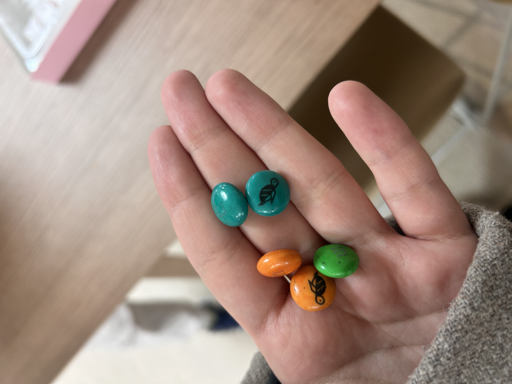

In [25]:
image = load_image(url, max_size=512)
content = [{"type": "image", "image": image}, {"type": "text", "text": "What animal is on the candy?"}]
inputs = prepare_inputs(content)
print("Resolution:", image.size)
print("Total tokens:", inputs["input_ids"].shape[-1])
image.show()

In [36]:
print(inference(content))

We need answer image question. Need inspect image. It shows small round candies/buttons? On orange candy there is black design. Need identify animal. Let's zoom mentally: orange candy has black symbol that looks like a treble clef? Wait question asks animal on candy. The teal candies have black design maybe a snail? Let's examine.

Image: hand holding four small oval candies. Two teal/greenish candies at top, two orange/green at bottom. On teal right candy: black marking looks like maybe a snail?


### Step-3: - Variable number of Loops

In [26]:
language_model = model.model.language_model
def set_loops(R):
    assert 1 <= R <= 5

    model.config.text_config.loop_num_passes = R
    language_model.config.loop_num_passes = R
language_model

Inkling2LoopTextModel(
  (embed_tokens): Inkling2LoopNormedEmbedding(
    201024, 2304
    (embed_norm): Inkling2LoopRMSNorm((2304,), eps=1e-06)
  )
  (layers): ModuleList(
    (0): Inkling2LoopSlidingDecoderLayer(
      (mlp_input): Inkling2LoopBlockAttentionResidual(
        (norm): Inkling2LoopUnweightedRMSNorm()
      )
      (self_attn): Inkling2LoopSlidingAttention(
        (q_proj): Inkling2LoopQueryProjection(
          (linear): Linear(in_features=2304, out_features=3072, bias=False)
          (norm): Inkling2LoopScaledL2Clip()
        )
        (k_proj): Inkling2LoopKeyValueProjection(
          (linear): Linear(in_features=2304, out_features=1024, bias=False)
          (sconv): Inkling2LoopShortConvolution(
            (conv1d): Conv1d(1024, 1024, kernel_size=(4,), stride=(1,), padding=(3,), groups=1024, bias=False)
          )
          (norm): Inkling2LoopL2Clip()
        )
        (v_proj): Inkling2LoopKeyValueProjection(
          (linear): Linear(in_features=2304, out_f

In [27]:
for R in range(1, 6):
    set_loops(R)
    print(R, language_model.config.loop_num_passes)

1 1
2 2
3 3
4 4
5 5


In [28]:
# from collections import Counter

# layer_calls = Counter()

# def count_hook(i):
#     def hook(module, args, output):
#         layer_calls[i] += 1
#     return hook

# handles = [
#     layer.register_forward_hook(count_hook(i))
#     for i, layer in enumerate(language_model.layers)
# ]

In [29]:
from collections import Counter

@torch.inference_mode()
def verify_loops(R):
    set_loops(R)

    counts = Counter()

    def make_hook(name):
        def hook(module, args, output):
            counts[name] += 1
        return hook

    handles = [
        layer.register_forward_hook(make_hook(i))
        for i, layer in enumerate(language_model.layers)
    ]

    handles.append(
        language_model.register_forward_hook(
            make_hook("decoder")
        )
    )

    try:
        out = model(
            **inputs,
            use_cache=False,
            logits_to_keep=1
        )
    finally:
        for h in handles:
            h.remove()

    print("R:", R)
    print("Decoder calls:", counts["decoder"])
    print("Prelude:", [counts[i] for i in range(6)])
    print("Core:", [counts[i] for i in range(6, 18)])
    print("Coda:", [counts[i] for i in range(18, 24)])

    return out.logits[0, -1].float().cpu()


@torch.inference_mode()
def test_loop_execution(R):
    set_loops(R)

    cfg = language_model.config
    calls = Counter()

    def count_hook(i):
        def hook(module, args, output):
            calls[i] += 1
        return hook

    handles = [
        layer.register_forward_hook(count_hook(i))
        for i, layer in enumerate(language_model.layers)
    ]

    try:
        out = model(
            **inputs,
            use_cache=False,
            logits_to_keep=1
        )
    finally:
        for h in handles:
            h.remove()

    expected = [
        R if cfg.loop_layer_index_start <= i < cfg.loop_layer_index_end
        else 1
        for i in range(len(language_model.layers))
    ]

    actual = [
        calls[i]
        for i in range(len(language_model.layers))
    ]

    print(f"R = {R}")
    print("Expected:", expected)
    print("Actual:  ", actual)
    print("Total executions:", sum(actual))
    print("Passed:", actual == expected)

    return out.logits[0, -1].float().cpu()

In [30]:
inputs = prepare_inputs(content)

In [31]:
# print("Loop count:", model.config.text_config.loop_num_passes)

# for i in range(24):
#     print(f"Layer {i:02d}: {layer_calls[i]} calls")

In [32]:
# cfg = language_model.config

# print("Number of layers:", len(language_model.layers))
# print("Loop start:", cfg.loop_layer_index_start)
# print("Loop end:", cfg.loop_layer_index_end)
# print("Loop passes:", cfg.loop_num_passes)

In [39]:
@torch.inference_mode()
def get_generation_logits(R):
    set_loops(R)

    out = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False,
        use_cache=True,
        return_dict_in_generate=True,
        output_logits=True
    )

    tokens = out.sequences[0, inputs["input_ids"].shape[-1]:]

    return {
        "tokens": tokens.cpu(),
        "logits": torch.stack(out.logits).squeeze(1).float().cpu(),
        "answer": processor.decode(tokens, skip_special_tokens=True)
    }

In [ ]:
generations = {R: get_generation_logits(R) for R in range(1, 6)}

for R, result in generations.items():
    print(f"R={R}: {result['answer']}")

R=1: We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify symbol on candies. Let's zoom mentally: image shows four round candies/buttons? Two teal/green on left, orange and green on right. On orange candy there is black symbol resembling a treble clef? Wait question asks animal. Maybe the black mark on candies is a snail? Let's examine.

The
R=2: We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify logo/design on candies. Let's zoom mentally. Image shows four candy-like oval candies in palm. Two teal/green candies with black design, two orange/green. The black design on orange candy looks like a treble clef? Wait question asks animal. Maybe the logo is a frog? Let's examine.
R=3: We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify logo/design on candies. Let's zoom mentally: image shows four small round candies/buttons? Teal candies h

In [41]:
for i, token in enumerate(generations[1]["tokens"]):
    print(i, repr(processor.decode([token.item()])))

0 '<|message_model|>'
1 '<|content_thinking|>'
2 'We'
3 ' need'
4 ' answer'
5 ' image'
6 ' question'
7 '.'
8 ' Need'
9 ' inspect'
10 ' image'
11 '.'
12 ' User'
13 ' asks'
14 ' what'
15 ' animal'
16 ' is'
17 ' on'
18 ' the'
19 ' '
20 'candy'
21 '.'
22 ' Need'
23 ' identify'
24 ' symbol'
25 ' on'
26 ' cand'
27 'ies'
28 '.'
29 ' Let'
30 "'"
31 's'
32 ' zoom'
33 ' ment'
34 'ally'
35 ':'
36 ' image'
37 ' shows'
38 ' four'
39 ' round'
40 ' cand'
41 'ies'
42 '/'
43 'buttons'
44 '?'
45 ' Two'
46 ' '
47 'teal'
48 '/'
49 'green'
50 ' on'
51 ' left'
52 ','
53 ' orange'
54 ' and'
55 ' green'
56 ' on'
57 ' right'
58 '.'
59 ' On'
60 ' orange'
61 ' '
62 'candy'
63 ' there'
64 ' is'
65 ' black'
66 ' symbol'
67 ' '
68 'resembl'
69 'ing'
70 ' a'
71 ' '
72 'treble'
73 ' '
74 'clef'
75 '?'
76 ' Wait'
77 ' question'
78 ' asks'
79 ' animal'
80 '.'
81 ' Maybe'
82 ' the'
83 ' black'
84 ' mark'
85 ' on'
86 ' cand'
87 'ies'
88 ' is'
89 ' a'
90 ' '
91 'snail'
92 '?'
93 ' Let'
94 "'"
95 's'
96 ' examine'
97 '.'
9

### Compare Output Distibutions 

In [42]:
t = 12

reference = generations[1]["logits"][t].double()

for R, result in generations.items():
    assert torch.equal(
        result["tokens"][:t],
        generations[1]["tokens"][:t]
    )

    z = result["logits"][t].double()

    kl = F.kl_div(
        z.log_softmax(-1),
        reference.softmax(-1),
        reduction="sum"
    ).item()

    print(f"R={R}, KL={kl:.6f}, Token={processor.decode([z.argmax().item()])}")

R=1, KL=0.000000, Token= User
R=2, KL=0.010508, Token= User
R=3, KL=0.028745, Token= User
R=4, KL=0.036395, Token= It
R=5, KL=0.031374, Token= It
